# 03 — Risk Measures : duration, convexité et DV01

Ce notebook quantifie la **sensibilité d'une obligation aux variations de taux** à travers les principales mesures de risque :

1. **Duration de Macaulay** : maturité moyenne pondérée des flux.
2. **Duration modifiée** : sensibilité relative du prix au taux.
3. **Convexité** : courbure de la relation prix-rendement (second ordre).
4. **DV01** : variation du prix pour un choc de 1 bp.
5. **Approximation de Taylor** : comparaison entre prix exact et approximations d'ordre 1 et 2.
6. **DV01 sur courbe** et **key-rate DV01** : répartition du risque par pilier.
7. **Application** : couverture DV01-neutre et illustration du risque de pente.

**Formules clés :**
- Duration de Macaulay : $D_{Mac} = \dfrac{\sum t_i \cdot PV(CF_i)}{P}$
- Duration modifiée : $D_{mod} = \dfrac{D_{Mac}}{1+y}$
- Convexité : $C = \dfrac{1}{P}\sum t_i(t_i+1)\dfrac{CF_i}{(1+y)^{t_i+2}}$
- Approx. Taylor : $\Delta P \approx -D_{mod} \cdot P \cdot \Delta y + \dfrac{1}{2} \cdot C \cdot P \cdot (\Delta y)^2$

## 1. Imports et configuration

On ajoute la racine du projet au chemin Python pour importer les modules `src.bonds`, `src.curve` et `src.risk` :
- `src.bonds` : `cashflows`, `bond_price`.
- `src.curve` : `bootstrap_par_curve`, `par_on_annual_grid`.
- `src.risk` : `macaulay_duration`, `modified_duration`, `convexity`, `dv01`, `price_approx`, `dv01_bump`, `dv01_curve`, `key_rate_dv01`.

La recherche de la racine est robuste : on remonte d'un niveau si nécessaire pour localiser `src/__init__.py`.

In [4]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src" / "__init__.py").is_file():
    project_root = project_root.parent
if not (project_root / "src" / "__init__.py").is_file():
    raise FileNotFoundError("Could not locate the project root containing src/__init__.py")
sys.path.insert(0, str(project_root))

from src.bonds import cashflows, bond_price
from src.curve import bootstrap_par_curve, par_on_annual_grid
from src.risk import (macaulay_duration, modified_duration, convexity, dv01,
                  price_approx, dv01_bump, dv01_curve, key_rate_dv01)

## 2. Mesures de risque par maturité

On calcule pour des obligations de maturités 2, 5, 10, 20 et 30 ans (même coupon 5 %, même YTM 4 %) :
- le prix,
- la duration de Macaulay,
- la duration modifiée,
- la convexité,
- le DV01.

**Observations attendues :**
- Duration et convexité **augmentent avec la maturité** — le risque de taux est plus élevé pour les obligations longues.
- La duration de Macaulay reste **inférieure à la maturité** pour une obligation à coupons (les coupons intermédiaires réduisent la maturité moyenne).
- Le DV01 croît également avec la maturité mais pas proportionnellement : le prix joue aussi un rôle.

In [5]:
y = 0.04
rows = []
for T in [2, 5, 10, 20, 30]:
    t, cf = cashflows(100, 0.05, T)
    rows.append({"maturité": T,
                 "prix": bond_price(t, cf, y),
                 "D Macaulay": macaulay_duration(t, cf, y),
                 "D modifiée": modified_duration(t, cf, y),
                 "convexité": convexity(t, cf, y),
                 "DV01": dv01(t, cf, y)})
pd.DataFrame(rows).round(4)

,maturité,prix,D Macaulay,D modifiée,convexité,DV01
0,2,101.8861,1.9528,1.8777,5.3728,0.0191
1,5,104.4518,4.5571,4.3818,24.4766,0.0458
2,10,108.1109,8.1909,7.8759,77.4820,0.0851
3,20,113.5903,13.5447,13.0238,225.8538,0.1479
4,30,117.2920,17.1941,16.5327,391.0011,0.1939


## 3. Effet du coupon sur la duration

À maturité fixée (10 ans), on fait varier le taux de coupon de 0 % (zéro-coupon) à 8 %.

**Observations attendues :**
- Un **zéro-coupon** a une duration de Macaulay **exactement égale à sa maturité** (un seul flux terminal).
- Plus le coupon est élevé, plus la duration **diminue** : les coupons intermédiaires remboursent une partie du capital plus tôt.
- La convexité suit la même tendance décroissante avec le coupon.
- Le prix augmente mécaniquement avec le coupon (plus de cash-flows).

**Message clé** : la duration n'est pas uniquement une affaire de maturité, elle dépend aussi du profil de flux.

In [6]:
rows = []
for c in [0.0, 0.02, 0.05, 0.08]:
    t, cf = cashflows(100, c, 10)
    rows.append({"coupon": c, "prix": bond_price(t, cf, y),
                 "D Macaulay": macaulay_duration(t, cf, y),
                 "D modifiée": modified_duration(t, cf, y),
                 "convexité": convexity(t, cf, y)})
pd.DataFrame(rows).round(4)

,coupon,prix,D Macaulay,D modifiée,convexité
0,0.00,67.5564,10.0000,9.6154,101.7012
1,0.02,83.7782,9.0662,8.7175,89.1998
2,0.05,108.1109,8.1909,7.8759,77.4820
3,0.08,132.4436,7.6372,7.3435,70.0698


## 4. Duration en fonction de la maturité

On trace la duration de Macaulay pour des maturités de 1 à 60 ans, pour trois niveaux de coupon (0 %, 3 %, 6 %).

**Observations attendues :**
- Le **zéro-coupon** suit la diagonale $D = T$ (droite pointillée noire).
- Les obligations à **coupons** ont une duration qui **plafonne** à mesure que la maturité augmente : asymptotiquement, $D_{Mac} \to \frac{1+y}{y}$ pour des coupons perpétuels.
- Plus le coupon est élevé, plus la duration est comprimée à toute maturité.

**Message clé** : la duration d'une obligation à coupons ne diverge pas avec la maturité — elle converge vers une limite.

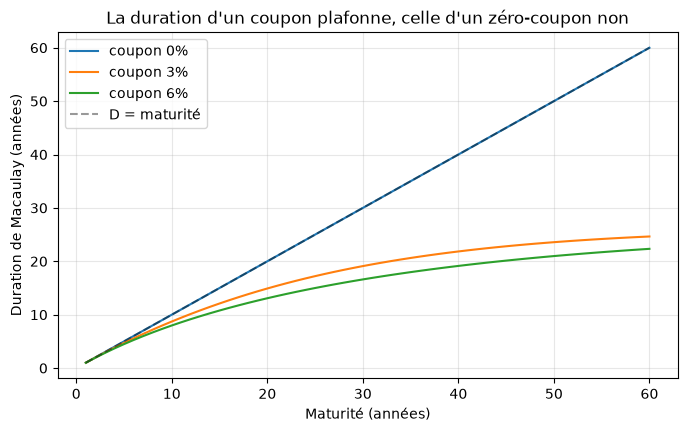

In [7]:
Ts = np.arange(1, 61)
plt.figure(figsize=(8, 4.5))
for c in [0.0, 0.03, 0.06]:
    d = [macaulay_duration(*cashflows(100, c, T), y) for T in Ts]
    plt.plot(Ts, d, label=f"coupon {c:.0%}")
plt.plot(Ts, Ts, "k--", alpha=0.4, label="D = maturité")
plt.xlabel("Maturité (années)"); plt.ylabel("Duration de Macaulay (années)")
plt.title("La duration d'un coupon plafonne, celle d'un zéro-coupon non")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5. Approximations d'ordre 1 et 2

On compare trois courbes autour de $y_0 = 5\%$ :
- **Prix exact** : calcul direct par actualisation.
- **Approximation d'ordre 1** (duration seule) : $\Delta P \approx -D_{mod} \cdot P \cdot \Delta y$.
- **Approximation d'ordre 2** (duration + convexité) : ajout du terme $\frac{1}{2} C P (\Delta y)^2$.

Le panneau de gauche montre les courbes ; celui de droite montre les **erreurs d'approximation**.

**Observations attendues :**
- L'approximation d'ordre 1 est une **droite tangente**, précise seulement pour de très petits chocs.
- L'approximation d'ordre 2 est une **parabole** qui colle à la courbe exacte sur une plage beaucoup plus large.
- Les erreurs d'ordre 1 sont **asymétriques** : plus grandes pour les baisses de taux (effet de la convexité).
- L'approximation d'ordre 2 corrige quasiment toute l'asymétrie.

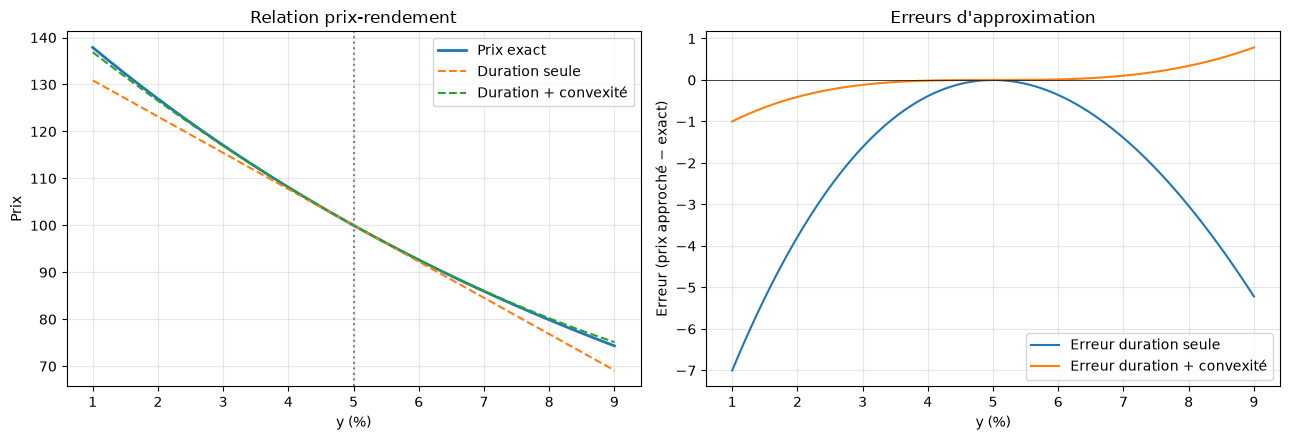

In [8]:
t, cf = cashflows(100, 0.05, 10)
y0 = 0.05
ys = np.linspace(0.01, 0.09, 200)
exact = np.array([bond_price(t, cf, v) for v in ys])
approx1 = np.array([price_approx(t, cf, y0, v - y0, order=1) for v in ys])
approx2 = np.array([price_approx(t, cf, y0, v - y0, order=2) for v in ys])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ys * 100, exact, label="Prix exact", lw=2)
axes[0].plot(ys * 100, approx1, "--", label="Duration seule")
axes[0].plot(ys * 100, approx2, "--", label="Duration + convexité")
axes[0].axvline(y0 * 100, color="gray", ls=":")
axes[0].set_xlabel("y (%)"); axes[0].set_ylabel("Prix"); axes[0].legend()
axes[0].set_title("Relation prix-rendement")

axes[1].plot(ys * 100, approx1 - exact, label="Erreur duration seule")
axes[1].plot(ys * 100, approx2 - exact, label="Erreur duration + convexité")
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_xlabel("y (%)"); axes[1].set_ylabel("Erreur (prix approché − exact)")
axes[1].legend(); axes[1].set_title("Erreurs d'approximation")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Tableau des erreurs par choc

On quantifie l'erreur d'approximation pour différents chocs allant de −200 bp à +200 bp, en comparant $\Delta P$ exact, l'erreur d'ordre 1 et l'erreur d'ordre 2.

**Observations attendues :**
- Pour un choc de **10 bp**, l'erreur d'ordre 1 est déjà de l'ordre de 0.004 — négligeable.
- Pour un choc de **±200 bp**, l'erreur d'ordre 1 dépasse 1.5 point de prix — significative.
- L'erreur d'ordre 2 reste faible même pour les gros chocs.
- On note que l'erreur d'ordre 1 est **du même signe** pour les hausses et les baisses, illustrant la **convexité positive**.

**Message clé** : pour des chocs modérés (< 50 bp), la duration seule suffit ; au-delà, la convexité devient indispensable.

In [9]:
rows = []
for bp in [-200, -100, -50, -10, 10, 50, 100, 200]:
    dy = bp / 1e4
    ex = bond_price(t, cf, y0 + dy)
    rows.append({"choc (bp)": bp, "ΔP exact": ex - bond_price(t, cf, y0),
                 "erreur ordre 1": price_approx(t, cf, y0, dy, order=1) - ex,
                 "erreur ordre 2": price_approx(t, cf, y0, dy, order=2) - ex})
pd.DataFrame(rows).round(5)

,choc (bp),ΔP exact,erreur ordre 1,erreur ordre 2
0,-200,17.06041,-1.61694,-0.11698
1,-100,8.11090,-0.38916,-0.01417
2,-50,3.95636,-0.09549,-0.00174
3,-10,0.77594,-0.00376,-0.00001
4,10,-0.76844,-0.00374,0.00001
5,50,-3.76881,-0.09205,0.00169
6,100,-7.36009,-0.36165,0.01334
7,200,-14.04716,-1.39631,0.10365


## 7. DV01 analytique vs numérique

On compare deux méthodes de calcul du DV01 :
- **Analytique** : $\text{DV01} = D_{mod} \cdot P \cdot 0.0001$ (dérivée première).
- **Numérique** (`dv01_bump`) : différence finie $\frac{P(y+1bp) - P(y)}{1}$.

Les deux valeurs doivent coïncider à la précision numérique près. C'est un **test de cohérence** entre l'implémentation analytique et la méthode par bump.

On illustre également l'**asymétrie** du risque :
- +100 bp : perte de −7.36
- −100 bp : gain de +8.11

La hausse fait perdre **moins** que la baisse ne fait gagner — c'est la **convexité** en action.

In [10]:
print("DV01 analytique :", dv01(t, cf, y0))
print("DV01 par bump   :", dv01_bump(t, cf, y0))

up = bond_price(t, cf, y0 + 0.01) - bond_price(t, cf, y0)
dn = bond_price(t, cf, y0 - 0.01) - bond_price(t, cf, y0)
print(f"+100 bp : {up:.3f} | -100 bp : {dn:.3f}   -> la hausse fait perdre moins que la baisse ne fait gagner")

DV01 analytique : 0.0772173492918481
DV01 par bump   : 0.07721736303741267
+100 bp : -7.360 | -100 bp : 8.111   -> la hausse fait perdre moins que la baisse ne fait gagner


## 8. DV01 sur courbe et key-rate DV01

On construit une courbe synthétique de taux au pair (maturités 1 à 10 ans), puis on calcule le DV01 d'une obligation 7 ans coupon 5 % selon trois approches :

1. **DV01 (y unique)** : on suppose un taux unique — hypothèse simplificatrice.
2. **DV01 (courbe parallèle)** : on bouge toute la courbe zéro-coupon de +1 bp — mesure plus réaliste.
3. **Key-rate DV01** : on bouge **un pilier à la fois** de +1 bp et on mesure l'impact.

**Observations attendues :**
- DV01 (y unique) **sous-estime** le DV01 réel de la courbe (les zéro-coupon utilisés ne sont pas tous égaux).
- La somme des key-rate DV01 **égale** le DV01 courbe parallèle (propriété d'additivité).
- Le graphique à barres montre que le risque est **concentré** sur les piliers proches de la maturité 7 ans, avec une contribution notable des coupons intermédiaires.

**Message clé** : le key-rate DV01 est l'outil de référence pour gérer un portefeuille obligataire face à des mouvements **non parallèles** de la courbe.

DV01 (y unique)        : 0.06223860478682045
DV01 (courbe parallèle): 0.0645194181215416
Somme des key-rate DV01: 0.0645194181215345


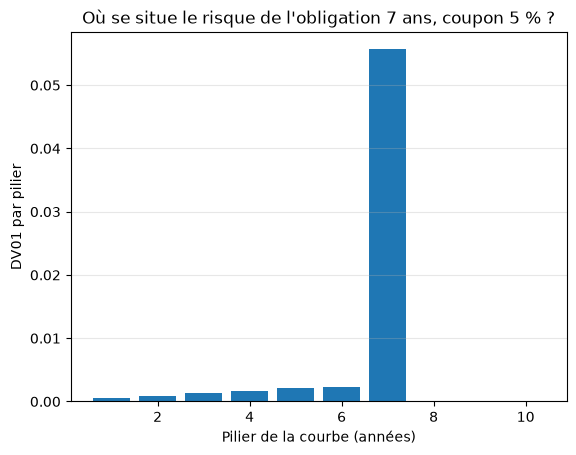

In [11]:
mats = np.arange(1, 11)
par = np.array([0.025, 0.027, 0.029, 0.031, 0.0325, 0.034, 0.035, 0.036, 0.0365, 0.037])
_, zeros = bootstrap_par_curve(mats, par)

t7, cf7 = cashflows(100, 0.05, 7)
print("DV01 (y unique)        :", dv01(t7, cf7, 0.04))
print("DV01 (courbe parallèle):", dv01_curve(t7, cf7, mats, zeros))

kr = key_rate_dv01(t7, cf7, mats, zeros)
print("Somme des key-rate DV01:", kr.sum())

plt.bar(mats, kr)
plt.xlabel("Pilier de la courbe (années)"); plt.ylabel("DV01 par pilier")
plt.title("Où se situe le risque de l'obligation 7 ans, coupon 5 % ?")
plt.grid(alpha=0.3, axis="y"); plt.show()

## 9. Application : key-rate DV01 sur courbe US réelle

On reprend la même obligation 7 ans coupon 5 % mais on utilise la **courbe US Treasury réelle** au 3 juillet 2023 (chargée depuis `us_par_yields.csv` généré dans le notebook 02).

On bootstrappe la courbe zéro-coupon, puis on calcule les key-rate DV01 sur les piliers disponibles.

**Observations attendues :**
- La forme du profil de risque dépend de la **structure par terme réelle** du jour considéré.
- Les piliers 5, 7 et 10 ans concentrent l'essentiel du risque.
- La somme des key-rate DV01 reste égale au DV01 courbe parallèle.

**Message clé** : la décomposition key-rate DV01 est un outil **opérationnel** de gestion du risque — elle indique précisément où se situe l'exposition et sur quels piliers intervenir pour couvrir.

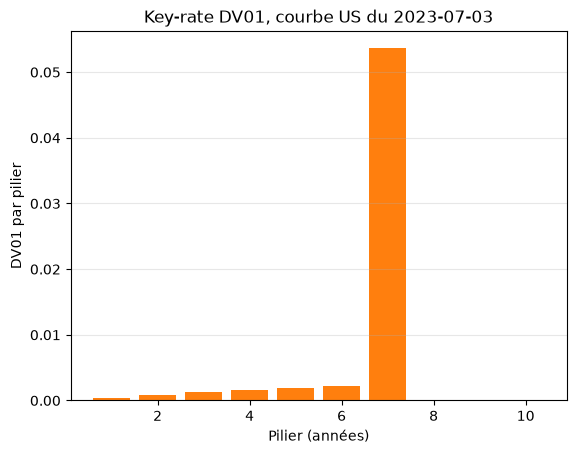

In [12]:
curves = pd.read_csv("../data/us_par_yields.csv", index_col=0, parse_dates=True)
curves.columns = curves.columns.astype(int)
row = curves.loc[:"2023-07-03"].iloc[-1]
m_us, p_us = par_on_annual_grid(row.index.values, row.values)
_, z_us = bootstrap_par_curve(m_us, p_us)

kr_us = key_rate_dv01(t7, cf7, m_us, z_us)
plt.bar(m_us, kr_us, color="tab:orange")
plt.xlabel("Pilier (années)"); plt.ylabel("DV01 par pilier")
plt.title("Key-rate DV01, courbe US du 2023-07-03"); plt.grid(alpha=0.3, axis="y"); plt.show()

## 10. Couverture DV01-neutre et risque de pente

On illustre un cas classique de gestion de portefeuille obligataire :

- Position longue de 10 M€ de nominal sur une obligation 10 ans coupon 4 %.
- Couverture par une position courte sur une obligation 2 ans coupon 3 %.
- Calcul du **nominal à vendre** pour neutraliser le DV01 total.

Puis on simule un scénario de **pentification** : le 10 ans monte de +50 bp, le 2 ans reste inchangé.

**Observations attendues :**
- Le DV01 total du portefeuille couvert est **neutre** (par construction).
- Mais dans le scénario de pentification, le P&L est **négatif** — la couverture DV01 ne protège que contre les mouvements **parallèles**.
- Le risque résiduel est un **risque de pente** (steepening/flattening), non capturé par le DV01 global.

**Message clé** : être DV01-neutre ne signifie pas être **immunisé**. Pour se protéger contre les mouvements non parallèles, il faut utiliser les **key-rate DV01** et couvrir pilier par pilier.

In [13]:
t2, cf2 = cashflows(100, 0.03, 2)
t10, cf10 = cashflows(100, 0.04, 10)
y2, y10 = 0.035, 0.04

notional_10 = 10_000_000                       # position longue sur 10 ans
dv01_10 = dv01(t10, cf10, y10) / 100 * notional_10
dv01_2  = dv01(t2, cf2, y2) / 100              # par unité de nominal
hedge_notional = dv01_10 / dv01_2

print(f"DV01 position 10 ans : {dv01_10:,.0f}")
print(f"Nominal 2 ans à vendre pour neutraliser le DV01 : {hedge_notional:,.0f}")

# Scénario : pentification (le 10 ans monte de 50 bp, le 2 ans ne bouge pas)
pnl_10 = (bond_price(t10, cf10, y10 + 0.005) - bond_price(t10, cf10, y10)) / 100 * notional_10
pnl_2 = -(bond_price(t2, cf2, y2) - bond_price(t2, cf2, y2)) / 100 * hedge_notional
print(f"P&L pentification : {pnl_10 + pnl_2:,.0f}  -> le DV01 total est neutre, pas le risque de courbe")

DV01 position 10 ans : 8,111
Nominal 2 ans à vendre pour neutraliser le DV01 : 43,005,644
P&L pentification : -395,636  -> le DV01 total est neutre, pas le risque de courbe
